# Notebook 05 — Diagnostics of Baseline-01 (NO training)
Solar Filament Segmentation Challenge 2026 — Kaggle edition

**What this notebook does (all on the saved Baseline-01 checkpoints, nothing is retrained):**
1. **BatchNorm / stability test** — Baseline-01's validation loss spiked at epochs 5, 24, 34, 40, 41, 44 and the monitored PQ was 0.000 at epoch 40.
   We re-evaluate the epoch 30/40/50 snapshots and the best checkpoint twice: as saved, and after re-estimating the BatchNorm
   running statistics. If the spikes disappear, stale BN statistics are a likely cause.
2. **Error anatomy** — where do the 1201 false positives and 397 misses come from (size, fragments vs. pure false alarms)?
3. **Post-processing sensitivity** — PQ as a function of threshold / minimum instance size / hole-closing, with an honest
   split-half protocol (choose on half A of the validation dates, report on half B, and vice versa).
4. **Annotator agreement under the SAME evaluator** — how well do the other annotation records agree with the primary record?
5. **Per-image breakdowns** (sparse images, stations).

**Setup (Kaggle right panel):** *Add Input* -> (a) the competition `filament-segmentation-2026`, (b) the **Notebook output of your saved
Baseline-01 FULL version** (its Output tab must list `baseline_best.pth`). Accelerator: GPU. Then *Save & Run All*.

The baseline numbers (PQ pooled 0.2881 on 139 val images at threshold 0.5) are reproduced as a sanity check first.
These are **diagnostics, not a new baseline**: any threshold / size-filter finding is a hypothesis for a separate, controlled experiment.

In [1]:
# ============================================================
# CONFIGURATION — the only cell you should need to edit
# ============================================================

# Competition data: attach it via "Add Input". Path is auto-detected (notebooks 1 and 2 used the first one).
KAGGLE_DATA_CANDIDATES = [
    "/kaggle/input/competitions/filament-segmentation-2026",
    "/kaggle/input/filament-segmentation-2026",
]

RUN_MODE = "FULL"               # <<< REAL Baseline-01.  ("SMOKE" | "PILOT" | "FULL", see the markdown cell above)
assert RUN_MODE in ("SMOKE", "PILOT", "FULL"), "RUN_MODE must be SMOKE, PILOT or FULL"
DEBUG_MODE = (RUN_MODE == "SMOKE")   # reduced-image-count shortcuts exist ONLY in SMOKE mode

OUTPUT_DIR = "/kaggle/working"  # kept only if you "Save Version"; see markdown above

SEED = 42
RESUME = True                   # resume from latest valid checkpoint if one exists

# ---- experiment parameters (Baseline-01) — same field names as Notebook 03 ----
CFG = {
    "experiment_id": "Baseline-01" if RUN_MODE == "FULL" else f"Baseline-01-{RUN_MODE}",
    "train_resolution": 512 if DEBUG_MODE else 1024,
    "batch_size": 2 if DEBUG_MODE else 4,
    "epochs": {"SMOKE": 20, "PILOT": 3, "FULL": 50}[RUN_MODE],
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "model": "UNet-base32",
    "loss": "BCE+Dice",
    "prob_threshold": 0.5,       # single configurable baseline threshold (NOT tuned)
    "min_instance_px": 0,        # no size filtering in the baseline
    "debug_n_train": 24,         # smoke-test only
    "debug_n_val": 8,            # smoke-test only
    # ---- run-infrastructure settings (do not change the methodology) ----
    "use_amp": True,             # automatic mixed precision for training / val loss
    "num_workers": None,         # None -> min(4, cpu_count)
    "pq_eval_every": 10,         # monitor val PQ every N epochs (0 = only final). Monitoring only.
    "snapshot_every": 10,        # keep a full-state snapshot every N epochs
    "ckpt_every": 2,             # write latest_checkpoint.pth every N epochs (and always at the last epoch)
    "fsync_checkpoints": False,  # fsync was a suspected cause of slow saves on Kaggle disk; atomic rename is kept
}

print(f"RUN_MODE={RUN_MODE} (DEBUG_MODE={DEBUG_MODE}) | resolution={CFG['train_resolution']} "
      f"| epochs={CFG['epochs']} | batch={CFG['batch_size']} | AMP={CFG['use_amp']}")

RUN_MODE=FULL (DEBUG_MODE=False) | resolution=1024 | epochs=50 | batch=4 | AMP=True


In [2]:
import os, sys, json, random, re, warnings, math, shutil, time, hashlib, platform, gc, datetime, copy
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU available (no CPU fallback). Kaggle panel -> Session options -> Accelerator -> GPU.")
DEVICE = torch.device("cuda:0")
CFG["num_workers"] = min(4, os.cpu_count() or 2)
print(f"torch {torch.__version__} | {torch.cuda.get_device_name(0)} | workers {CFG['num_workers']}")

OUT = Path(OUTPUT_DIR) / "diagnostics"; OUT.mkdir(parents=True, exist_ok=True)

# ---- locate the saved Baseline-01 FULL output (attached as an Input) ----
# Searches for the CHECKPOINT FILE anywhere under /kaggle/input (the notebook's title does not matter).
hits = sorted(Path("/kaggle/input").rglob("baseline_best.pth"))
print("baseline_best.pth found at:", [str(h) for h in hits] if hits else "NOWHERE")
if not hits:
    print("\nWhat is mounted under /kaggle/input (depth <= 3):")
    for root, dirs, files in os.walk("/kaggle/input"):
        depth = root[len("/kaggle/input"):].count(os.sep)
        if depth <= 3:
            pth = [f for f in files if f.endswith(".pth")]
            print(f"  {root}  | files: {len(files)}" + (f" | .pth: {pth[:6]}" if pth else ""))
    raise FileNotFoundError(
        "No baseline_best.pth under /kaggle/input.\n"
        "The input you added contains no checkpoint files. Most likely the saved version has an EMPTY Output tab "
        "(Quick Save, still running, or failed). Open that notebook on Kaggle -> the version -> 'Output' tab: it must list "
        "baseline_best.pth, latest_checkpoint.pth, checkpoint_epoch_0X0.pth ... If it is empty, re-run the Baseline-01 FULL "
        "notebook with 'Save & Run All' and wait for the version to finish, then add THAT version's output as the input.")
PREV = max((h.parent for h in hits), key=lambda p: p.stat().st_mtime)
print("Baseline-01 output folder used:", PREV)
print("files:", sorted(p.name for p in PREV.iterdir()))

torch 2.11.0+cu128 | Tesla T4 | workers 4
baseline_best.pth found at: ['/kaggle/input/notebooks/parsabehjattabrizi/baseline-best/full/baseline_best.pth']
Baseline-01 output folder used: /kaggle/input/notebooks/parsabehjattabrizi/baseline-best/full
files: ['baseline_best.pth', 'baseline_best_meta.json', 'baseline_report.txt', 'baseline_results.csv', 'checkpoint_epoch_010.pth', 'checkpoint_epoch_020.pth', 'checkpoint_epoch_030.pth', 'checkpoint_epoch_040.pth', 'checkpoint_epoch_050.pth', 'experiment_log.csv', 'iou_dice_dist.png', 'latest_checkpoint.pth', 'latest_checkpoint_prev.pth', 'per_image_metrics.csv', 'run_config.json', 'split_metadata.csv', 'training_curve.png', 'training_history.csv', 'validation_gallery.png', 'validation_gallery_worst3.png']


In [3]:
# ============================================================
# DATA DISCOVERY on Kaggle (/kaggle/input) — same discovery logic as Notebook 03
# ============================================================

def acquire_data_root():
    for c in KAGGLE_DATA_CANDIDATES:
        if Path(c).exists():
            return Path(c)
    base = Path("/kaggle/input")
    if base.exists() and any(base.rglob("train_images")):
        print("WARNING: standard path not found; using /kaggle/input and auto-discovery.")
        return base
    raise FileNotFoundError(
        "Competition data not found under /kaggle/input.\n"
        "Fix: right-hand panel -> Add Input -> search 'filament-segmentation-2026' -> Add.")

DATA_ROOT = acquire_data_root()
print("DATA_ROOT:", DATA_ROOT)

IMG_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def discover_dataset(root):
    """Find train/test image dirs and the COCO annotation JSON. Fail loudly."""
    img_dirs = []
    for d in sorted({p.parent for p in root.rglob("*") if p.suffix.lower() in IMG_EXTS}):
        n = sum(1 for p in d.iterdir() if p.suffix.lower() in IMG_EXTS)
        img_dirs.append((d, n))
        print(f"  image dir: {d.relative_to(root)}  ({n} images)")
    train_cands = [d for d, _ in img_dirs
                   if "train" in str(d).lower() and "test" not in str(d).lower()]
    test_cands = [d for d, _ in img_dirs
                  if "test" in str(d).lower() and "train" not in str(d).lower()]
    if len(train_cands) != 1 or len(test_cands) != 1:
        raise RuntimeError(
            f"Ambiguous dataset layout. train candidates={train_cands}, "
            f"test candidates={test_cands}. Inspect the listing above.")
    coco = None
    for p in root.rglob("*.json"):
        try:
            with open(p) as f:
                d = json.load(f)
            if isinstance(d, dict) and "images" in d and "annotations" in d:
                coco = p; break
        except Exception:
            pass
    if coco is None:
        raise RuntimeError(f"No COCO-style annotation JSON found under {root}")
    return train_cands[0], test_cands[0], coco

TRAIN_DIR, TEST_DIR, ANN_PATH = discover_dataset(DATA_ROOT)

train_paths = sorted(p for p in TRAIN_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
test_paths  = sorted(p for p in TEST_DIR.iterdir()  if p.suffix.lower() in IMG_EXTS)
name_to_path = {p.name: p for p in train_paths}

print(f"\ntrain images: {len(train_paths)} | test images: {len(test_paths)}")
print(f"annotations: {ANN_PATH.name}")
assert len(train_paths) > 0 and len(test_paths) > 0

DATA_ROOT: /kaggle/input/competitions/filament-segmentation-2026
  image dir: MAGFiLO_1.0_Kaggle_2026/test/test_images  (180 images)
  image dir: MAGFiLO_1.0_Kaggle_2026/train/train_images  (707 images)

train images: 707 | test images: 180
annotations: MAGFiLO_1.0_Annotations_kaggle2026_train.json


In [4]:
# ============================================================
# ANNOTATIONS + BASELINE GT REPRESENTATION  (unchanged from Notebook 03)
# Baseline target = FIRST annotation record per file (sorted by id).
# ============================================================

def load_annotations(path):
    with open(path) as f:
        coco = json.load(f)
    images_info = {im["id"]: im for im in coco["images"]}
    anns_by_image = defaultdict(list)
    for a in coco["annotations"]:
        anns_by_image[a["image_id"]].append(a)
    return coco, images_info, anns_by_image

COCO, images_info, anns_by_image = load_annotations(ANN_PATH)
print(f"JSON records: {len(images_info)} | annotations: {len(COCO['annotations'])}")

file_to_records = defaultdict(list)
for img_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in name_to_path:
        file_to_records[fname].append(img_id)

missing = len(images_info) - sum(len(v) for v in file_to_records.values())
if missing:
    raise RuntimeError(f"{missing} JSON records reference files not on disk")

file_to_primary = {f: sorted(ids)[0] for f, ids in file_to_records.items()}
primary_ids = sorted(file_to_primary.values())
print(f"physical files: {len(file_to_primary)} | primary records: {len(primary_ids)}")

def ann_to_mask(ann, h, w):
    m = np.zeros((h, w), np.uint8)
    for poly in ann["segmentation"]:
        pts = np.asarray(poly, np.float64).reshape(-1, 2)
        cv2.fillPoly(m, [np.round(pts).astype(np.int32)], 1)
    return m.astype(bool)

def build_gt_masks(img_id):
    """Full-resolution instance masks for one record."""
    info = images_info[img_id]
    masks = [ann_to_mask(a, info["height"], info["width"])
             for a in anns_by_image[img_id]]
    masks = [m for m in masks if m.any()]
    if not masks:
        raise ValueError(f"Record {img_id} has no non-empty GT masks")
    return masks

def load_image(path):
    img = np.array(Image.open(path))
    if img.ndim == 3:
        img = img[..., :3].mean(axis=2)
    return img.astype(np.float32)

JSON records: 1154 | annotations: 8199
physical files: 707 | primary records: 707


In [5]:
# ============================================================
# OFFICIAL EVALUATOR REPRODUCTION
# Many-to-many matching: EVERY (pred, gt) pair with IoU > 0.5 (STRICT >)
# is a TP and contributes its IoU to the numerator.
# FP = pred with zero qualifying matches; FN = gt with zero.
# PQ = sum(TP IoUs) / (TP + 0.5 FP + 0.5 FN)
# Diagnostics (one-to-many / many-to-one) use overlap > 0.
#
# Only change vs Notebook 03: the pairwise IoU/Dice loop skips pairs whose
# bounding boxes do not intersect and only intersects the bbox overlap region.
# Results are mathematically identical (verified against the original
# implementation in the equivalence test below); it is just much faster.
# ============================================================

def _bbox(m):
    rows = np.flatnonzero(m.any(axis=1)); cols = np.flatnonzero(m.any(axis=0))
    if len(rows) == 0:
        return (0, 0, 0, 0)
    return (rows[0], rows[-1] + 1, cols[0], cols[-1] + 1)

def iou_and_dice_matrix(pred_masks, gt_masks):
    n_p, n_g = len(pred_masks), len(gt_masks)
    iou = np.zeros((n_p, n_g)); dce = np.zeros((n_p, n_g))
    pb = [_bbox(p) for p in pred_masks]; gb = [_bbox(g) for g in gt_masks]
    pa = [int(p.sum()) for p in pred_masks]; ga = [int(g.sum()) for g in gt_masks]
    for i, p in enumerate(pred_masks):
        py0, py1, px0, px1 = pb[i]
        for j, g in enumerate(gt_masks):
            gy0, gy1, gx0, gx1 = gb[j]
            y0, y1 = max(py0, gy0), min(py1, gy1)
            x0, x1 = max(px0, gx0), min(px1, gx1)
            if y0 >= y1 or x0 >= x1:
                continue
            inter = int(np.logical_and(p[y0:y1, x0:x1], g[y0:y1, x0:x1]).sum())
            if inter == 0:
                continue
            iou[i, j] = inter / (pa[i] + ga[j] - inter)
            dce[i, j] = 2 * inter / (pa[i] + ga[j])
    return iou, dce

def compute_official_pq(gt_masks, pred_masks):
    if len(gt_masks) == 0 and len(pred_masks) == 0:
        return {"PQ": 1.0, "TP": 0, "FP": 0, "FN": 0,
                "tp_ious": [], "tp_dices": [],
                "one_to_many": 0, "many_to_one": 0}
    iou, dce = iou_and_dice_matrix(pred_masks, gt_masks)
    hit = iou > 0.5                                   # STRICT >
    tp_ious = iou[hit].tolist()
    tp_dices = dce[hit].tolist()
    tp = len(tp_ious)
    fp = int((hit.sum(axis=1) == 0).sum()) if len(pred_masks) else 0
    fn = int((hit.sum(axis=0) == 0).sum()) if len(gt_masks) else 0
    denom = tp + 0.5 * fp + 0.5 * fn
    overlap = iou > 0
    one_to_many = int((overlap.sum(axis=0) > 1).sum())   # GT hit by multiple preds
    many_to_one = int((overlap.sum(axis=1) > 1).sum())   # pred hitting multiple GTs
    return {"PQ": (sum(tp_ious) / denom) if denom > 0 else 0.0,
            "TP": tp, "FP": fp, "FN": fn,
            "tp_ious": tp_ious, "tp_dices": tp_dices,
            "one_to_many": one_to_many, "many_to_one": many_to_one}

# ---------------- MANDATORY UNIT TESTS (same 7 as Notebook 03) ----------------
def _box(y0, y1, x0, x1, hw=64):
    m = np.zeros((hw, hw), bool); m[y0:y1, x0:x1] = True; return m

def run_metric_tests():
    results = []
    g = _box(10, 20, 10, 30)                       # 10x20 = 200 px

    r = compute_official_pq([g], [g.copy()])
    results.append(("T1 perfect -> PQ=1", abs(r["PQ"] - 1.0) < 1e-9))

    half = _box(10, 20, 10, 20)                    # IoU = 0.5 exactly
    r = compute_official_pq([g], [half])
    results.append(("T2 IoU==0.5 not TP", r["TP"] == 0 and r["FP"] == 1 and r["FN"] == 1))

    most = _box(10, 20, 10, 24)                    # IoU = 0.7
    r = compute_official_pq([g], [most])
    results.append(("T3 IoU>0.5 is TP", r["TP"] == 1 and r["FP"] == 0 and r["FN"] == 0))

    p1 = _box(10, 20, 10, 27); p2 = _box(10, 20, 12, 30)
    r = compute_official_pq([g], [p1, p2])
    results.append(("T4 1 GT + 2 preds -> TP=2 FP=0 FN=0",
                    r["TP"] == 2 and r["FP"] == 0 and r["FN"] == 0))

    g1 = _box(10, 20, 10, 30); g2 = _box(10, 20, 8, 32); pred = _box(10, 20, 9, 31)
    r = compute_official_pq([g1, g2], [pred])
    results.append(("T5 2 GT + 1 pred -> TP=2 FP=0 FN=0",
                    r["TP"] == 2 and r["FP"] == 0 and r["FN"] == 0))

    r = compute_official_pq([g], [])
    results.append(("T6 no preds -> FN=1, PQ=0", r["FN"] == 1 and r["PQ"] == 0.0))

    r = compute_official_pq([], [g])
    results.append(("T7 no GT -> FP=1, PQ=0", r["FP"] == 1 and r["PQ"] == 0.0))

    all_ok = True
    for name, ok in results:
        print(f"  {'PASS' if ok else 'FAIL'}  {name}")
        all_ok &= ok
    if not all_ok:
        raise AssertionError("Metric unit tests FAILED — do not proceed")
    print("All 7 metric tests passed.")

run_metric_tests()

# ---------------- EQUIVALENCE TEST: fast matrix == original Notebook-03 matrix ----------------
def _iou_and_dice_matrix_reference(pred_masks, gt_masks):
    """Verbatim original implementation from Notebook 03 (slow, full-frame)."""
    n_p, n_g = len(pred_masks), len(gt_masks)
    iou = np.zeros((n_p, n_g)); dce = np.zeros((n_p, n_g))
    for i, p in enumerate(pred_masks):
        ps = p.sum()
        for j, g in enumerate(gt_masks):
            inter = np.logical_and(p, g).sum()
            if inter == 0:
                continue
            gs = g.sum()
            iou[i, j] = inter / (ps + gs - inter)
            dce[i, j] = 2 * inter / (ps + gs)
    return iou, dce

def run_equivalence_test(n_trials=40, hw=96):
    rng = np.random.RandomState(0)
    def rand_mask():
        m = np.zeros((hw, hw), np.uint8)
        for _ in range(rng.randint(1, 4)):
            y, x = rng.randint(0, hw - 8, 2); h, w = rng.randint(2, 30, 2)
            m[y:y + h, x:x + w] = 1
        return m.astype(bool)
    for _ in range(n_trials):
        P = [rand_mask() for _ in range(rng.randint(0, 6))]
        G = [rand_mask() for _ in range(rng.randint(0, 6))]
        a = iou_and_dice_matrix(P, G); b = _iou_and_dice_matrix_reference(P, G)
        assert np.allclose(a[0], b[0]) and np.allclose(a[1], b[1]), "fast IoU/Dice differs from original"
    print(f"Equivalence test passed: fast evaluator == original on {n_trials} random cases.")

run_equivalence_test()

  PASS  T1 perfect -> PQ=1
  PASS  T2 IoU==0.5 not TP
  PASS  T3 IoU>0.5 is TP
  PASS  T4 1 GT + 2 preds -> TP=2 FP=0 FN=0
  PASS  T5 2 GT + 1 pred -> TP=2 FP=0 FN=0
  PASS  T6 no preds -> FN=1, PQ=0
  PASS  T7 no GT -> FP=1, PQ=0
All 7 metric tests passed.
Equivalence test passed: fast evaluator == original on 40 random cases.


In [6]:
# ============================================================
# SPLIT — date-grouped 80/20 (Notebook 02 A3). Same function, same seed as Notebook 03.
# ============================================================

FN_RE = re.compile(r"^(\d{4})(\d{2})(\d{2})\d{6}([A-Za-z])h\.", re.I)

def create_split(primary_ids, val_frac=0.2, seed=SEED):
    rows = []
    for img_id in primary_ids:
        fname = Path(images_info[img_id]["file_name"]).name
        m = FN_RE.match(fname)
        if not m:
            raise ValueError(f"Unparseable filename: {fname}")
        rows.append({"img_id": img_id, "file": fname,
                     "date": f"{m[1]}-{m[2]}-{m[3]}", "station": m[4].upper()})
    df = pd.DataFrame(rows)
    dates = sorted(df["date"].unique())
    rng = random.Random(seed); rng.shuffle(dates)
    n_val_dates = int(round(len(dates) * val_frac))
    val_dates = set(dates[:n_val_dates])
    df["split"] = df["date"].map(lambda d: "val" if d in val_dates else "train")
    return df

split_df = create_split(primary_ids)
train_ids = split_df.loc[split_df.split == "train", "img_id"].tolist()
val_ids   = split_df.loc[split_df.split == "val", "img_id"].tolist()

if DEBUG_MODE:                       # smoke-test shortcut — must be OFF for Baseline-01
    train_ids = train_ids[:CFG["debug_n_train"]]
    val_ids   = val_ids[:CFG["debug_n_val"]]

SPLIT_HASH = hashlib.sha1(",".join(sorted(
    split_df.loc[split_df.split == "val", "file"])).encode()).hexdigest()[:12]

split_df.to_csv(OUT / "split_metadata.csv", index=False)
print(f"train: {len(train_ids)} | val: {len(val_ids)} (date-grouped) | split hash: {SPLIT_HASH}")
assert not set(split_df[split_df.split == "train"].date) & \
           set(split_df[split_df.split == "val"].date)

train: 568 | val: 139 (date-grouped) | split hash: 0cc2d729a5b1


In [7]:
# ============================================================
# DATASET — fixed-size tensors. Preprocessing and augmentation (h/v flips only)
# are IDENTICAL to Notebook 03.
# ============================================================

class FilamentDataset(Dataset):
    def __init__(self, record_ids, resolution, augment=False):
        self.ids = record_ids
        self.res = resolution
        self.augment = augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_id = self.ids[idx]
        info = images_info[img_id]
        fname = Path(info["file_name"]).name
        img = load_image(name_to_path[fname])
        h, w = img.shape

        gt = np.zeros((h, w), bool)
        for a in anns_by_image[img_id]:
            gt |= ann_to_mask(a, h, w)

        img = cv2.resize(img, (self.res, self.res), interpolation=cv2.INTER_AREA)
        gt = cv2.resize(gt.astype(np.uint8), (self.res, self.res),
                        interpolation=cv2.INTER_NEAREST).astype(bool)

        lo, hi = np.percentile(img, [1, 99])
        img = np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1).astype(np.float32)

        if self.augment:
            if random.random() < 0.5:
                img = np.fliplr(img).copy(); gt = np.fliplr(gt).copy()
            if random.random() < 0.5:
                img = np.flipud(img).copy(); gt = np.flipud(gt).copy()

        return {"image": torch.from_numpy(img)[None],
                "mask": torch.from_numpy(gt.astype(np.float32))[None],
                "img_id": img_id}

def _worker_init(_):
    cv2.setNumThreads(0)

train_ds = FilamentDataset(train_ids, CFG["train_resolution"], augment=True)
val_ds   = FilamentDataset(val_ids, CFG["train_resolution"], augment=False)

# generator is re-seeded every epoch (SEED + epoch) so shuffling/augmentation is reproducible
# and identical whether or not the run was resumed.
train_gen = torch.Generator(); train_gen.manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,
                          num_workers=CFG["num_workers"], pin_memory=True, drop_last=True,
                          generator=train_gen, worker_init_fn=_worker_init)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False,
                        num_workers=CFG["num_workers"], pin_memory=True,
                        worker_init_fn=_worker_init)

# sample check WITHOUT creating DataLoader iterators (avoids the dangling-worker noise seen in Notebook 03)
_s = train_ds[0]
print("sample check:", tuple(_s["image"].shape), tuple(_s["mask"].shape),
      "| train batches/epoch:", len(train_loader), "| val images:", len(val_ds))
del _s

sample check: (1, 1024, 1024) (1, 1024, 1024) | train batches/epoch: 142 | val images: 139


In [8]:
# ============================================================
# MODEL — plain U-Net (base 32), UNCHANGED.  Loss — BCE + soft Dice, UNCHANGED
# (logits are cast to float32 inside the loss so AMP cannot affect the loss math).
# ============================================================

class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    def __init__(self, cin=1, base=32):
        super().__init__()
        self.e1, self.e2 = ConvBlock(cin, base), ConvBlock(base, base*2)
        self.e3, self.e4 = ConvBlock(base*2, base*4), ConvBlock(base*4, base*8)
        self.pool = nn.MaxPool2d(2)
        self.mid = ConvBlock(base*8, base*16)
        self.u4 = nn.ConvTranspose2d(base*16, base*8, 2, 2); self.d4 = ConvBlock(base*16, base*8)
        self.u3 = nn.ConvTranspose2d(base*8, base*4, 2, 2);  self.d3 = ConvBlock(base*8, base*4)
        self.u2 = nn.ConvTranspose2d(base*4, base*2, 2, 2);  self.d2 = ConvBlock(base*4, base*2)
        self.u1 = nn.ConvTranspose2d(base*2, base, 2, 2);    self.d1 = ConvBlock(base*2, base)
        self.out = nn.Conv2d(base, 1, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        m = self.mid(self.pool(e4))
        d = self.d4(torch.cat([self.u4(m), e4], 1))
        d = self.d3(torch.cat([self.u3(d), e3], 1))
        d = self.d2(torch.cat([self.u2(d), e2], 1))
        d = self.d1(torch.cat([self.u1(d), e1], 1))
        return self.out(d)

def build_model():
    return UNet(1, 32).to(DEVICE)

def build_optimizer(model):
    return torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])

def bce_dice_loss(logits, target, eps=1.0):
    logits = logits.float()
    bce = nn.functional.binary_cross_entropy_with_logits(logits, target)
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum(dim=(2, 3))
    dice = (2 * inter + eps) / (prob.sum(dim=(2, 3)) + target.sum(dim=(2, 3)) + eps)
    return bce + (1 - dice).mean()

USE_AMP = bool(CFG["use_amp"]) and DEVICE.type == "cuda"

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)

def build_scaler():
    return torch.amp.GradScaler("cuda", enabled=USE_AMP)

EXPECTED_PARAMS = 7_765_409      # parameter count reported by the Notebook 03 smoke test
_tmp_model = build_model()
N_PARAMS = sum(p.numel() for p in _tmp_model.parameters())
del _tmp_model
print(f"parameters: {N_PARAMS:,} | AMP: {USE_AMP}")

parameters: 7,765,409 | AMP: True


In [9]:
# ============================================================
# INFERENCE + VALIDATION UNDER THE OFFICIAL METRIC (per-image, full 2048)
# Inference for PQ is done in FP32 (identical to Notebook 03).
# ============================================================

@torch.no_grad()
def predict_image(model, img_path, resolution):
    """Returns full-2048 probability map."""
    img = load_image(img_path)
    h, w = img.shape
    small = cv2.resize(img, (resolution, resolution), interpolation=cv2.INTER_AREA)
    lo, hi = np.percentile(small, [1, 99])
    small = np.clip((small - lo) / max(hi - lo, 1e-6), 0, 1).astype(np.float32)
    x = torch.from_numpy(small)[None, None].to(DEVICE)
    prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()
    return cv2.resize(prob, (w, h), interpolation=cv2.INTER_LINEAR)

def extract_instances(prob, threshold, min_px=0):
    """Probability map -> list of boolean instance masks via connected components."""
    binary = (prob > threshold).astype(np.uint8)
    n, labels = cv2.connectedComponents(binary, connectivity=8)
    out = []
    for k in range(1, n):
        m = labels == k
        if m.sum() > min_px:
            out.append(m)
    return out

def evaluate_validation(model, ids, threshold, desc="validation"):
    """Official-metric evaluation over ALL images in `ids`."""
    model.eval()
    rows, all_tp_ious, all_tp_dices = [], [], []
    agg = Counter()
    for img_id in tqdm(ids, desc=desc, leave=False):
        fname = Path(images_info[img_id]["file_name"]).name
        gt = build_gt_masks(img_id)
        prob = predict_image(model, name_to_path[fname], CFG["train_resolution"])
        preds = extract_instances(prob, threshold, CFG["min_instance_px"])
        r = compute_official_pq(gt, preds)
        all_tp_ious += r["tp_ious"]; all_tp_dices += r["tp_dices"]
        for k in ["TP", "FP", "FN", "one_to_many", "many_to_one"]:
            agg[k] += r[k]
        rows.append({"img_id": img_id, "file": fname,
                     "n_gt": len(gt), "n_pred": len(preds),
                     "PQ": r["PQ"], "TP": r["TP"], "FP": r["FP"], "FN": r["FN"],
                     "one_to_many": r["one_to_many"], "many_to_one": r["many_to_one"],
                     "mean_tp_iou": float(np.mean(r["tp_ious"])) if r["tp_ious"] else np.nan,
                     "mean_tp_dice": float(np.mean(r["tp_dices"])) if r["tp_dices"] else np.nan})
    per_image = pd.DataFrame(rows)
    denom = agg["TP"] + 0.5 * agg["FP"] + 0.5 * agg["FN"]
    overall = {
        "PQ_pooled": float(sum(all_tp_ious) / denom) if denom else 0.0,
        "PQ_mean_per_image": float(per_image["PQ"].mean()),
        "TP": int(agg["TP"]), "FP": int(agg["FP"]), "FN": int(agg["FN"]),
        "mean_tp_iou": float(np.mean(all_tp_ious)) if all_tp_ious else 0.0,
        "mean_tp_dice": float(np.mean(all_tp_dices)) if all_tp_dices else 0.0,
        "one_to_many": int(agg["one_to_many"]), "many_to_one": int(agg["many_to_one"]),
        "n_images_evaluated": int(len(per_image)), "threshold": float(threshold),
    }
    return per_image, overall, all_tp_ious, all_tp_dices

In [10]:
# ============================================================
# CONSISTENCY WITH THE BASELINE RUN (same split, same weights format)
# ============================================================
prev_split = pd.read_csv(PREV / "split_metadata.csv")
prev_val = set(prev_split.loc[prev_split.split == "val", "file"])
now_val = set(split_df.loc[split_df.split == "val", "file"])
assert prev_val == now_val, "Validation split differs from the Baseline-01 run — stop."
print("Validation split identical to Baseline-01:", len(now_val), "files | hash", SPLIT_HASH)

prev_res = pd.read_csv(PREV / "baseline_results.csv").iloc[0] if (PREV / "baseline_results.csv").exists() else None
if prev_res is not None:
    print(f"Baseline-01 reported: PQ pooled {prev_res['PQ_pooled']:.4f} | mean/img {prev_res['PQ_mean_per_image']:.4f} | "
          f"TP {prev_res['TP']} FP {prev_res['FP']} FN {prev_res['FN']} | best epoch {prev_res['best_epoch']}")

# ---- guard: make sure this is the COMPLETED 50-epoch run, not a partial / in-progress version ----
hist_path, meta_path = PREV / "training_history.csv", PREV / "baseline_best_meta.json"
if hist_path.exists():
    n_ep = len(pd.read_csv(hist_path))
    print(f"training_history.csv in the input has {n_ep} epochs")
    if n_ep < CFG["epochs"]:
        raise RuntimeError(
            f"The Baseline-01 output you attached is INCOMPLETE ({n_ep}/{CFG['epochs']} epochs). It is probably a version that is "
            f"still running or failed. baseline_best.pth there is NOT the final best model. Wait until the version shows "
            f"'Complete' and re-attach its output. (Diagnostics on a partial run would be meaningless.)")
if meta_path.exists():
    meta = json.loads(meta_path.read_text())
    print(f"baseline_best.pth = epoch {meta['best_epoch']} (val loss {meta['best_val_loss']:.4f}); "
          f"the run you showed me had epoch 42, val loss 0.3619")
if prev_res is None:
    print("NOTE: baseline_results.csv not found in the input -> the automatic reproduction check will be skipped.")

def load_model(path):
    ck = torch.load(path, map_location="cpu", weights_only=True)
    sd = ck["model"] if isinstance(ck, dict) and "model" in ck else ck
    m = build_model(); m.load_state_dict(sd); m.eval()
    return m

@torch.no_grad()
def predict_small(model, img_path, resolution):
    """Same preprocessing as predict_image, but returns the probability map at model resolution (cacheable)."""
    img = load_image(img_path)
    small = cv2.resize(img, (resolution, resolution), interpolation=cv2.INTER_AREA)
    lo, hi = np.percentile(small, [1, 99])
    small = np.clip((small - lo) / max(hi - lo, 1e-6), 0, 1).astype(np.float32)
    x = torch.from_numpy(small)[None, None].to(DEVICE)
    return torch.sigmoid(model(x))[0, 0].cpu().numpy(), img.shape

best_model = load_model(PREV / "baseline_best.pth")
PROB = {}
for img_id in tqdm(val_ids, desc="cache val probabilities (best checkpoint)"):
    fname = Path(images_info[img_id]["file_name"]).name
    PROB[img_id] = predict_small(best_model, name_to_path[fname], CFG["train_resolution"])

def full_prob(img_id):
    p, (h, w) = PROB[img_id]
    return cv2.resize(p, (w, h), interpolation=cv2.INTER_LINEAR)     # identical to predict_image

print("cached", len(PROB), "probability maps")

Validation split identical to Baseline-01: 139 files | hash 0cc2d729a5b1
Baseline-01 reported: PQ pooled 0.2881 | mean/img 0.2974 | TP 611 FP 1201 FN 397 | best epoch 42
training_history.csv in the input has 50 epochs
baseline_best.pth = epoch 42 (val loss 0.3619); the run you showed me had epoch 42, val loss 0.3619


cache val probabilities (best checkpoint):   0%|          | 0/139 [00:00<?, ?it/s]

cached 139 probability maps


In [11]:
# ============================================================
# ANALYSIS HELPERS (numpy only)
# ============================================================
AREA_BINS = [0, 50, 200, 1000, 5000, 10**12]
BIN_LABELS = ["<50 px", "50-199", "200-999", "1000-4999", ">=5000"]

def area_bin(a):
    for i in range(len(AREA_BINS) - 1):
        if AREA_BINS[i] <= a < AREA_BINS[i + 1]:
            return i

def analyze_image(gt, preds):
    """Anatomy of the official-metric result for one image (areas in 2048-px space)."""
    iou, _ = iou_and_dice_matrix(preds, gt)
    hit = iou > 0.5
    ov = iou > 0
    pa = [int(p.sum()) for p in preds]; ga = [int(g.sum()) for g in gt]
    pred_rows, gt_rows = [], []
    for i in range(len(preds)):
        is_fp = not hit[i].any()
        pred_rows.append({"area": pa[i], "bin": area_bin(pa[i]), "FP": is_fp,
                          "overlaps_gt": bool(ov[i].any()), "n_gt_overlapped": int(ov[i].sum())})
    for j in range(len(gt)):
        n_ov = int(ov[:, j].sum()) if len(preds) else 0
        is_fn = not (hit[:, j].any() if len(preds) else False)
        cat = "matched"
        union_iou = np.nan
        if is_fn:
            if n_ov == 0:
                cat = "missed: no overlapping prediction"
            elif n_ov == 1:
                cat = "missed: 1 overlapping prediction (IoU<=0.5)"
            else:
                u = np.zeros_like(gt[j])
                for i in np.flatnonzero(ov[:, j]):
                    u |= preds[i]
                union_iou = float((u & gt[j]).sum() / max((u | gt[j]).sum(), 1))
                cat = ("missed: fragmented, merge WOULD match (union IoU>0.5)" if union_iou > 0.5
                       else "missed: fragmented, merge would NOT match")
        gt_rows.append({"area": ga[j], "bin": area_bin(ga[j]), "FN": is_fn, "n_pred_overlapping": n_ov,
                        "category": cat, "union_iou": union_iou})
    return pred_rows, gt_rows

def summarize(items):
    """items: list of compute_official_pq results -> pooled PQ etc."""
    tp = sum(r["TP"] for r in items); fp = sum(r["FP"] for r in items); fn = sum(r["FN"] for r in items)
    ious = [x for r in items for x in r["tp_ious"]]
    denom = tp + 0.5 * fp + 0.5 * fn
    return {"PQ_pooled": (sum(ious) / denom) if denom else 0.0,
            "PQ_mean_per_image": float(np.mean([r["PQ"] for r in items])) if items else 0.0,
            "TP": tp, "FP": fp, "FN": fn,
            "mean_tp_iou": float(np.mean(ious)) if ious else 0.0}

In [12]:
# ============================================================
# 2) ERROR ANATOMY of the best checkpoint (threshold 0.5, no filtering = Baseline-01 setting)
# ============================================================
pred_rows, gt_rows, img_rows, base_items = [], [], [], []
for img_id in tqdm(val_ids, desc="error anatomy"):
    prob = full_prob(img_id); gt = build_gt_masks(img_id)
    preds = extract_instances(prob, CFG["prob_threshold"], CFG["min_instance_px"])
    r = compute_official_pq(gt, preds); base_items.append(r)
    pr, gr = analyze_image(gt, preds)
    for x in pr: x["img_id"] = img_id
    for x in gr: x["img_id"] = img_id
    pred_rows += pr; gt_rows += gr
    img_rows.append({"img_id": img_id, "n_gt": len(gt), "n_pred": len(preds), "PQ": r["PQ"],
                     "TP": r["TP"], "FP": r["FP"], "FN": r["FN"]})
P = pd.DataFrame(pred_rows); G = pd.DataFrame(gt_rows); I = pd.DataFrame(img_rows)

base = summarize(base_items)
print("Reproduction of Baseline-01 on cached probabilities:", {k: round(v, 4) if isinstance(v, float) else v for k, v in base.items()})
if prev_res is not None:
    ok = abs(base["PQ_pooled"] - float(prev_res["PQ_pooled"])) < 5e-3 and base["TP"] == int(prev_res["TP"])
    print("  matches the saved Baseline-01 result:", "YES" if ok else "NO  <-- investigate before trusting the rest")

# ---- size breakdown ----
rows = []
for b, lab in enumerate(BIN_LABELS):
    pb = P[P.bin == b]; gb = G[G.bin == b]
    rows.append({"area_bin": lab, "n_pred": len(pb), "n_pred_FP": int(pb.FP.sum()),
                 "FP_rate": round(pb.FP.mean(), 3) if len(pb) else np.nan,
                 "n_gt": len(gb), "n_gt_FN": int(gb.FN.sum()),
                 "FN_rate": round(gb.FN.mean(), 3) if len(gb) else np.nan})
size_df = pd.DataFrame(rows); size_df.to_csv(OUT / "size_breakdown.csv", index=False)
print("\nPredictions and ground truth by instance area (2048-px pixels):"); print(size_df.to_string(index=False))

# ---- where do false positives come from? ----
fp = P[P.FP]
print(f"\nFalse positives: {len(fp)} total")
print(f"  pure false alarms (touch NO ground truth):        {int((~fp.overlaps_gt).sum())}")
print(f"  overlap some GT but IoU<=0.5 (fragments/shape):   {int(fp.overlaps_gt.sum())}")

# ---- where do misses come from? ----
miss = G[G.FN]
print(f"\nMissed ground-truth instances: {len(miss)} of {len(G)}")
cat_df = miss.category.value_counts().rename_axis("category").reset_index(name="n_gt")
print(cat_df.to_string(index=False)); cat_df.to_csv(OUT / "miss_categories.csv", index=False)
n_rec = int((miss.category.str.contains("WOULD match")).sum())
print(f"  -> {n_rec} misses would be matched if their fragments were merged "
      f"(upper bound on what a fragment-merging step could recover).")

# ---- per-image views ----
I = I.merge(split_df[["img_id", "date", "station"]], on="img_id", how="left")
I["gt_bin"] = pd.cut(I.n_gt, [0, 2, 5, 10, 20, 1000], labels=["1-2", "3-5", "6-10", "11-20", ">20"])
print("\nPQ by number of GT instances in the image:")
print(I.groupby("gt_bin", observed=True).agg(n_images=("PQ", "size"), mean_PQ=("PQ", "mean"),
                                              FP=("FP", "sum"), FN=("FN", "sum")).round(3).to_string())
print("\nPQ by station letter:")
print(I.groupby("station").agg(n_images=("PQ", "size"), mean_PQ=("PQ", "mean")).round(3).to_string())
I.to_csv(OUT / "per_image_best_thr05.csv", index=False)

error anatomy:   0%|          | 0/139 [00:00<?, ?it/s]

Reproduction of Baseline-01 on cached probabilities: {'PQ_pooled': 0.2881, 'PQ_mean_per_image': 0.2974, 'TP': 611, 'FP': 1201, 'FN': 397, 'mean_tp_iou': 0.6649}
  matches the saved Baseline-01 result: YES

Predictions and ground truth by instance area (2048-px pixels):
 area_bin  n_pred  n_pred_FP  FP_rate  n_gt  n_gt_FN  FN_rate
   <50 px     177        177    1.000     0        0      NaN
   50-199     224        222    0.991     2        1    0.500
  200-999     737        531    0.720   377      136    0.361
1000-4999     601        254    0.423   537      210    0.391
   >=5000      73         17    0.233    92       50    0.543

False positives: 1201 total
  pure false alarms (touch NO ground truth):        608
  overlap some GT but IoU<=0.5 (fragments/shape):   593

Missed ground-truth instances: 397 of 1008
                                             category  n_gt
          missed: 1 overlapping prediction (IoU<=0.5)   171
            missed: fragmented, merge would NOT match

threshold x min-size sweep:   0%|          | 0/139 [00:00<?, ?it/s]

Pooled PQ on ALL 139 validation images (rows: threshold, columns: min instance px):
min_px       0      25     50     100    200    400
threshold                                          
0.3        0.282  0.294  0.302  0.312  0.328  0.348
0.4        0.285  0.297  0.304  0.314  0.330  0.350
0.5        0.288  0.300  0.308  0.319  0.335  0.352
0.6        0.291  0.305  0.312  0.323  0.341  0.358
0.7        0.292  0.305  0.313  0.325  0.341  0.358

Baseline setting (thr 0.5, min 0): PQ_A 0.2927 | PQ_B 0.2833
Best on half A: thr 0.7, min_px 400 -> A 0.3679, held-out B 0.3473  (baseline B 0.2833, change +0.0640)
Best on half B: thr 0.6, min_px 400 -> B 0.3489, held-out A 0.3658  (baseline A 0.2927, change +0.0732)
Average held-out gain from threshold/min-size post-processing: +0.0686 PQ


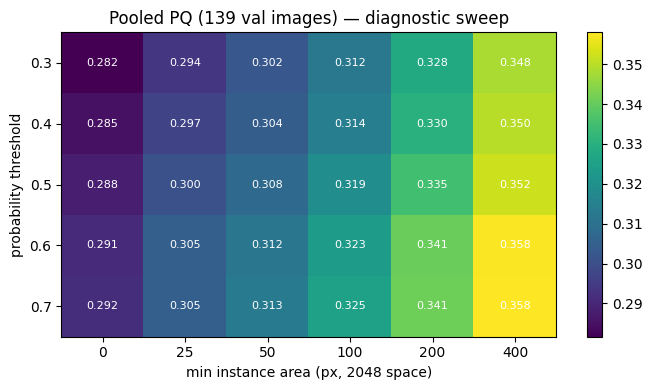

In [13]:
# ============================================================
# 3) POST-PROCESSING SENSITIVITY (diagnostic, NOT a tuned baseline)
# Protocol: validation dates are split into halves A/B (alternating sorted dates).
# We pick the best setting on one half and REPORT it on the other half, so the gain is not just selection noise.
# ============================================================
THRS = [0.3, 0.4, 0.5, 0.6, 0.7]
MINS = [0, 25, 50, 100, 200, 400]            # min instance area in 2048-px pixels (strictly greater is kept)

vsplit = split_df[split_df.img_id.isin(val_ids)]
date_half = {d: "AB"[i % 2] for i, d in enumerate(sorted(vsplit.date.unique()))}
img_half = {r.img_id: date_half[r.date] for r in vsplit.itertuples()}

RES = {(t, m): [] for t in THRS for m in MINS}
for img_id in tqdm(val_ids, desc="threshold x min-size sweep"):
    prob = full_prob(img_id); gt = build_gt_masks(img_id)
    for t in THRS:
        n, labels = cv2.connectedComponents((prob > t).astype(np.uint8), connectivity=8)
        areas = np.bincount(labels.ravel(), minlength=n)
        comps = [(int(areas[k]), labels == k) for k in range(1, n)]
        for m_ in MINS:
            RES[(t, m_)].append((img_id, compute_official_pq(gt, [mk for a, mk in comps if a > m_])))
        del comps

rows = []
for (t, m_), items in RES.items():
    allr = [r for _, r in items]
    A = [r for i, r in items if img_half[i] == "A"]; B = [r for i, r in items if img_half[i] == "B"]
    s = summarize(allr)
    rows.append({"threshold": t, "min_px": m_, "PQ_all": s["PQ_pooled"], "PQ_A": summarize(A)["PQ_pooled"],
                 "PQ_B": summarize(B)["PQ_pooled"], "TP": s["TP"], "FP": s["FP"], "FN": s["FN"]})
sweep = pd.DataFrame(rows).sort_values(["threshold", "min_px"]).reset_index(drop=True)
sweep.to_csv(OUT / "postproc_sweep.csv", index=False)

piv = sweep.pivot(index="threshold", columns="min_px", values="PQ_all")
print("Pooled PQ on ALL 139 validation images (rows: threshold, columns: min instance px):")
print(piv.round(3).to_string())

b = sweep[(sweep.threshold == 0.5) & (sweep.min_px == 0)].iloc[0]
bestA = sweep.loc[sweep.PQ_A.idxmax()]; bestB = sweep.loc[sweep.PQ_B.idxmax()]
print(f"\nBaseline setting (thr 0.5, min 0): PQ_A {b.PQ_A:.4f} | PQ_B {b.PQ_B:.4f}")
print(f"Best on half A: thr {bestA.threshold}, min_px {int(bestA.min_px)} -> A {bestA.PQ_A:.4f}, "
      f"held-out B {bestA.PQ_B:.4f}  (baseline B {b.PQ_B:.4f}, change {bestA.PQ_B - b.PQ_B:+.4f})")
print(f"Best on half B: thr {bestB.threshold}, min_px {int(bestB.min_px)} -> B {bestB.PQ_B:.4f}, "
      f"held-out A {bestB.PQ_A:.4f}  (baseline A {b.PQ_A:.4f}, change {bestB.PQ_A - b.PQ_A:+.4f})")
HELD_OUT_GAIN = float(np.mean([bestA.PQ_B - b.PQ_B, bestB.PQ_A - b.PQ_A]))
print(f"Average held-out gain from threshold/min-size post-processing: {HELD_OUT_GAIN:+.4f} PQ")

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(piv.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(MINS))); ax.set_xticklabels(MINS); ax.set_yticks(range(len(THRS))); ax.set_yticklabels(THRS)
for i in range(len(THRS)):
    for j in range(len(MINS)):
        ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
ax.set_xlabel("min instance area (px, 2048 space)"); ax.set_ylabel("probability threshold")
ax.set_title("Pooled PQ (139 val images) — diagnostic sweep"); plt.colorbar(im); plt.tight_layout()
plt.savefig(OUT / "postproc_heatmap.png", dpi=110); plt.show()

In [14]:
# ============================================================
# 3b) FRAGMENT-MERGING PROBE: morphological closing of the binary mask (threshold 0.5, no size filter)
# ============================================================
CLOSE_R = [0, 3, 6, 10]                       # structuring-element radius in 2048-px pixels
CRES = {r_: [] for r_ in CLOSE_R}
for img_id in tqdm(val_ids, desc="closing sweep"):
    prob = full_prob(img_id); gt = build_gt_masks(img_id)
    binary = (prob > 0.5).astype(np.uint8)
    for r_ in CLOSE_R:
        bm = binary if r_ == 0 else cv2.morphologyEx(
            binary, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r_ + 1, 2 * r_ + 1)))
        n, labels = cv2.connectedComponents(bm, connectivity=8)
        CRES[r_].append((img_id, compute_official_pq(gt, [labels == k for k in range(1, n)])))

rows = []
for r_, items in CRES.items():
    allr = [r for _, r in items]
    A = [r for i, r in items if img_half[i] == "A"]; B = [r for i, r in items if img_half[i] == "B"]
    s = summarize(allr)
    rows.append({"closing_radius": r_, "PQ_all": s["PQ_pooled"], "PQ_A": summarize(A)["PQ_pooled"],
                 "PQ_B": summarize(B)["PQ_pooled"], "TP": s["TP"], "FP": s["FP"], "FN": s["FN"]})
close_df = pd.DataFrame(rows); close_df.to_csv(OUT / "closing_sweep.csv", index=False)
print(close_df.round(4).to_string(index=False))

closing sweep:   0%|          | 0/139 [00:00<?, ?it/s]

 closing_radius  PQ_all   PQ_A   PQ_B  TP   FP  FN
              0  0.2881 0.2927 0.2833 611 1201 397
              3  0.2984 0.3044 0.2919 618 1111 390
              6  0.3047 0.3117 0.2973 617 1042 391
             10  0.3115 0.3177 0.3049 617  972 391


In [15]:
# ============================================================
# 4) ANNOTATOR AGREEMENT UNDER THE SAME EVALUATOR
# For validation files that have >=2 annotation records: how well does another record match the primary record,
# and how does the MODEL score against each record? (A reference for label noise — not a performance ceiling.)
# ============================================================
ann_items, mod_prim, mod_other = [], [], []
n_files = 0
for img_id in tqdm(val_ids, desc="annotator agreement"):
    fname = Path(images_info[img_id]["file_name"]).name
    recs = sorted(file_to_records[fname])
    if len(recs) < 2:
        continue
    gt1 = build_gt_masks(recs[0])
    preds = extract_instances(full_prob(img_id), CFG["prob_threshold"], CFG["min_instance_px"])
    for rk in recs[1:]:
        try:
            gtk = build_gt_masks(rk)
        except ValueError:
            continue
        ann_items.append(compute_official_pq(gt1, gtk))        # other record treated as "prediction" vs primary
        mod_prim.append(compute_official_pq(gt1, preds))
        mod_other.append(compute_official_pq(gtk, preds))
    n_files += 1

print(f"validation files with >=2 annotation records: {n_files} ({len(ann_items)} record pairs)")
if ann_items:
    a, mp, mo = summarize(ann_items), summarize(mod_prim), summarize(mod_other)
    agree_df = pd.DataFrame([
        {"comparison": "other annotation record vs PRIMARY record", **a},
        {"comparison": "model vs PRIMARY record (same files)", **mp},
        {"comparison": "model vs OTHER record", **mo}])
    agree_df.to_csv(OUT / "annotator_agreement.csv", index=False)
    print(agree_df.round(4).to_string(index=False))
    print("\nNote: same official many-to-many evaluator; this differs from Notebook 02's greedy pairwise procedure, "
          "so the numbers need not equal 0.38. It is a label-noise reference, NOT a performance ceiling.")
else:
    agree_df = None

annotator agreement:   0%|          | 0/139 [00:00<?, ?it/s]

validation files with >=2 annotation records: 59 (86 record pairs)
                               comparison  PQ_pooled  PQ_mean_per_image  TP  FP  FN  mean_tp_iou
other annotation record vs PRIMARY record     0.3769             0.3695 353 246 260       0.6470
     model vs PRIMARY record (same files)     0.2599             0.2768 352 797 261       0.6506
                    model vs OTHER record     0.2920             0.3001 377 772 222       0.6769

Note: same official many-to-many evaluator; this differs from Notebook 02's greedy pairwise procedure, so the numbers need not equal 0.38. It is a label-noise reference, NOT a performance ceiling.


In [16]:
# ============================================================
# 1) BATCHNORM / STABILITY TEST on saved checkpoints
# For each checkpoint: evaluate AS SAVED, then after re-estimating BatchNorm running statistics on ~240 training images
# (weights untouched). Large jumps => the running statistics were stale/unstable at that epoch.
# ============================================================
def val_loss(model):
    model.eval(); tot = 0.0
    loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=CFG["num_workers"], worker_init_fn=_worker_init)
    with torch.no_grad():
        for b in loader:
            img = b["image"].to(DEVICE); msk = b["mask"].to(DEVICE)
            with autocast_ctx():
                logits = model(img)
            tot += bce_dice_loss(logits, msk).item()
    return tot / len(loader)

def recalibrate_bn(model, n_batches=60):
    m = copy.deepcopy(model)
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.reset_running_stats(); mod.momentum = None        # cumulative average over the batches below
    g = torch.Generator(); g.manual_seed(SEED)
    loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True, num_workers=CFG["num_workers"],
                        drop_last=True, generator=g, worker_init_fn=_worker_init)
    it = iter(loader); m.train()
    with torch.no_grad():
        for _ in range(n_batches):
            b = next(it)
            with autocast_ctx():
                m(b["image"].to(DEVICE))
    del it; m.eval()
    return m

CKPTS = [("best (epoch 42 in Baseline-01)", PREV / "baseline_best.pth")]
for ep in (30, 40, 50):
    p = PREV / f"checkpoint_epoch_{ep:03d}.pth"
    if p.exists():
        CKPTS.append((f"snapshot epoch {ep}", p))
print("checkpoints to test:", [n for n, _ in CKPTS])

rows = []
for name, path in CKPTS:
    m = load_model(path)
    vl0 = val_loss(m); _, o0, _, _ = evaluate_validation(m, val_ids, 0.5, desc=f"{name}: as saved")
    mr = recalibrate_bn(m)
    vl1 = val_loss(mr); _, o1, _, _ = evaluate_validation(mr, val_ids, 0.5, desc=f"{name}: BN re-estimated")
    rows.append({"checkpoint": name, "val_loss_as_saved": vl0, "PQ_as_saved": o0["PQ_pooled"], "FP_as_saved": o0["FP"],
                 "val_loss_BN_reestimated": vl1, "PQ_BN_reestimated": o1["PQ_pooled"], "FP_BN_reestimated": o1["FP"]})
    print(f"{name}: val loss {vl0:.4f} -> {vl1:.4f} | PQ {o0['PQ_pooled']:.4f} -> {o1['PQ_pooled']:.4f}")
    del m, mr; gc.collect(); torch.cuda.empty_cache()

bn_df = pd.DataFrame(rows); bn_df.to_csv(OUT / "bn_diagnostic.csv", index=False)
print(); print(bn_df.round(4).to_string(index=False))
gain = (bn_df.PQ_BN_reestimated - bn_df.PQ_as_saved)
print("\nVERDICT (indicative only):")
if (gain > 0.05).any():
    print("  BN re-estimation changes PQ by more than +0.05 on at least one checkpoint -> stale/unstable BatchNorm "
          "running statistics are a likely contributor to the validation spikes.")
else:
    print("  BN re-estimation does NOT materially change PQ -> BatchNorm statistics are probably not the (main) cause; "
          "look at learning-rate/optimisation instability instead.")

checkpoints to test: ['best (epoch 42 in Baseline-01)', 'snapshot epoch 30', 'snapshot epoch 40', 'snapshot epoch 50']


best (epoch 42 in Baseline-01): as saved:   0%|          | 0/139 [00:00<?, ?it/s]

best (epoch 42 in Baseline-01): BN re-estimated:   0%|          | 0/139 [00:00<?, ?it/s]

best (epoch 42 in Baseline-01): val loss 0.3619 -> 0.3636 | PQ 0.2881 -> 0.2751


snapshot epoch 30: as saved:   0%|          | 0/139 [00:00<?, ?it/s]

snapshot epoch 30: BN re-estimated:   0%|          | 0/139 [00:00<?, ?it/s]

... (3 outputs left out)

snapshot epoch 40: val loss 1.0411 -> 0.3777 | PQ 0.0000 -> 0.2702


snapshot epoch 50: as saved:   0%|          | 0/139 [00:00<?, ?it/s]

snapshot epoch 50: BN re-estimated:   0%|          | 0/139 [00:00<?, ?it/s]

snapshot epoch 50: val loss 0.5163 -> 0.3606 | PQ 0.2254 -> 0.2953

                    checkpoint  val_loss_as_saved  PQ_as_saved  FP_as_saved  val_loss_BN_reestimated  PQ_BN_reestimated  FP_BN_reestimated
best (epoch 42 in Baseline-01)             0.3619       0.2881         1201                   0.3636             0.2751               1421
             snapshot epoch 30             0.3805       0.2522         1381                   0.3722             0.2631               1374
             snapshot epoch 40             1.0411       0.0000            2                   0.3777             0.2702               1307
             snapshot epoch 50             0.5163       0.2254          673                   0.3606             0.2953               1106

VERDICT (indicative only):
  BN re-estimation changes PQ by more than +0.05 on at least one checkpoint -> stale/unstable BatchNorm running statistics are a likely contributor to the validation spikes.


In [17]:
# ============================================================
# SUMMARY — copy this block back to Claude
# ============================================================
lines = []
add = lines.append
add("DIAGNOSTICS SUMMARY (Baseline-01, best checkpoint unless stated; validation = 139 images)")
add("-" * 70)
add(f"Reproduced baseline: PQ pooled {base['PQ_pooled']:.4f} | TP {base['TP']} FP {base['FP']} FN {base['FN']}")
sq = base["mean_tp_iou"]; rq = base["TP"] / max(base["TP"] + 0.5 * base["FP"] + 0.5 * base["FN"], 1e-9)
add(f"PQ decomposition: segmentation quality (mean matched IoU) {sq:.3f} x detection quality {rq:.3f}")
add("")
add("FP anatomy: " + f"{len(fp)} FP -> {int((~fp.overlaps_gt).sum())} pure false alarms, {int(fp.overlaps_gt.sum())} overlap a GT but IoU<=0.5")
add("FN anatomy:"); [add(f"   {r.category}: {r.n_gt}") for r in cat_df.itertuples()]
add("")
add("Size breakdown (area bin | preds, FP rate | GT, FN rate):")
[add(f"   {r.area_bin:>10} | {r.n_pred:5d}, {r.FP_rate} | {r.n_gt:5d}, {r.FN_rate}") for r in size_df.itertuples()]
add("")
add(f"Post-processing sweep: best on A -> held-out B change {bestA.PQ_B - b.PQ_B:+.4f}; best on B -> held-out A change {bestB.PQ_A - b.PQ_A:+.4f}; "
    f"mean held-out gain {HELD_OUT_GAIN:+.4f}")
add(f"   best-on-A setting: thr {bestA.threshold}, min_px {int(bestA.min_px)} | best-on-B setting: thr {bestB.threshold}, min_px {int(bestB.min_px)}")
add("Closing sweep (radius: PQ_all): " + ", ".join(f"{int(r.closing_radius)}: {r.PQ_all:.4f}" for r in close_df.itertuples()))
if agree_df is not None:
    add("")
    add("Annotator agreement (same evaluator):")
    [add(f"   {r.comparison}: PQ pooled {r.PQ_pooled:.4f}, mean/img {r.PQ_mean_per_image:.4f}") for r in agree_df.itertuples()]
add("")
add("BN test (PQ as saved -> BN re-estimated):")
[add(f"   {r.checkpoint}: {r.PQ_as_saved:.4f} -> {r.PQ_BN_reestimated:.4f}  (val loss {r.val_loss_as_saved:.3f} -> {r.val_loss_BN_reestimated:.3f})") for r in bn_df.itertuples()]
add("")
add("PQ by #GT in image: " + "; ".join(f"{k}: {v:.3f}" for k, v in I.groupby('gt_bin', observed=True).PQ.mean().items()))
add("CAVEAT: all sweeps are diagnostics on the validation set that also selected the checkpoint; treat gains as hypotheses.")
report = "\n".join(lines)
print(report)
(OUT / "diagnostics_report.txt").write_text(report)
print("\nSaved to", OUT, ":", sorted(p.name for p in OUT.iterdir()))

DIAGNOSTICS SUMMARY (Baseline-01, best checkpoint unless stated; validation = 139 images)
----------------------------------------------------------------------
Reproduced baseline: PQ pooled 0.2881 | TP 611 FP 1201 FN 397
PQ decomposition: segmentation quality (mean matched IoU) 0.665 x detection quality 0.433

FP anatomy: 1201 FP -> 608 pure false alarms, 593 overlap a GT but IoU<=0.5
FN anatomy:
   missed: 1 overlapping prediction (IoU<=0.5): 171
   missed: fragmented, merge would NOT match: 78
   missed: fragmented, merge WOULD match (union IoU>0.5): 77
   missed: no overlapping prediction: 71

Size breakdown (area bin | preds, FP rate | GT, FN rate):
       <50 px |   177, 1.0 |     0, nan
       50-199 |   224, 0.991 |     2, 0.5
      200-999 |   737, 0.72 |   377, 0.361
    1000-4999 |   601, 0.423 |   537, 0.391
       >=5000 |    73, 0.233 |    92, 0.543

Post-processing sweep: best on A -> held-out B change +0.0640; best on B -> held-out A change +0.0732; mean held-out gain 